# Wprowadzenie do uczenia maszynowego - Lista 3
Konrad Słotta 277442

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import os
import kagglehub

## Zadanie 1

Współczynnik kierunkowy ($\beta_1$):$$\beta_1 = \frac{\sum_{i=1}^{n} (x_i - \bar{x})(y_i - \bar{y})}{\sum_{i=1}^{n} (x_i - \bar{x})^2} = \frac{\text{Cov}(X, Y)}{\text{Var}(X)}$$Wyraz wolny ($\beta_0$):$$\beta_0 = \bar{y} - \beta_1 \bar{x}$$

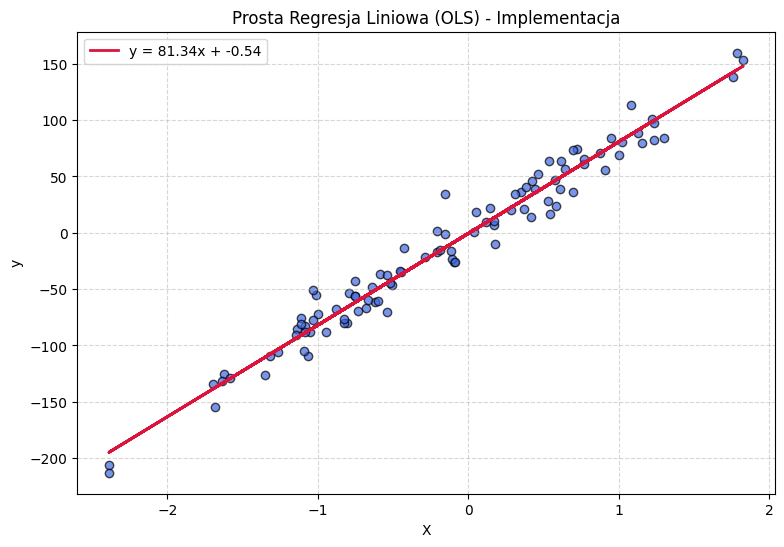

In [6]:
from sklearn.datasets import make_regression

class CustomLinearRegressionOLS:
    def __init__(self):
        self.slope_ = None
        self.intercept_ = None

    def fit(self, X, y):
        x_flat = np.array(X).flatten()
        y_flat = np.array(y).flatten()

        x_mean = np.mean(x_flat)
        y_mean = np.mean(y_flat)

        self.slope_ = np.sum((x_flat - x_mean) * (y_flat - y_mean)) / np.sum((x_flat - x_mean) ** 2)
        self.intercept_ = y_mean - (self.slope_ * x_mean)
        return self

    def predict(self, X):
        x_flat = np.array(X).flatten()
        return self.slope_ * x_flat + self.intercept_

X1, y1 = make_regression(
    n_samples=100, 
    n_features=1, 
    noise=15.0, 
    random_state=67
)

custom_model = CustomLinearRegressionOLS()
custom_model.fit(X1, y1)

plt.figure(figsize=(9, 6))
plt.scatter(X1, y1, color='royalblue', alpha=0.7, edgecolors='k', label='')

y_pred1 = custom_model.predict(X1)
plt.plot(X1, y_pred1, color='crimson', linewidth=2, label=f'y = {custom_model.slope_:.2f}x + {custom_model.intercept_:.2f}')

plt.title('Prosta Regresja Liniowa (OLS) - Implementacja', fontsize=12)
plt.xlabel('X')
plt.ylabel('y')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## Zadanie 2

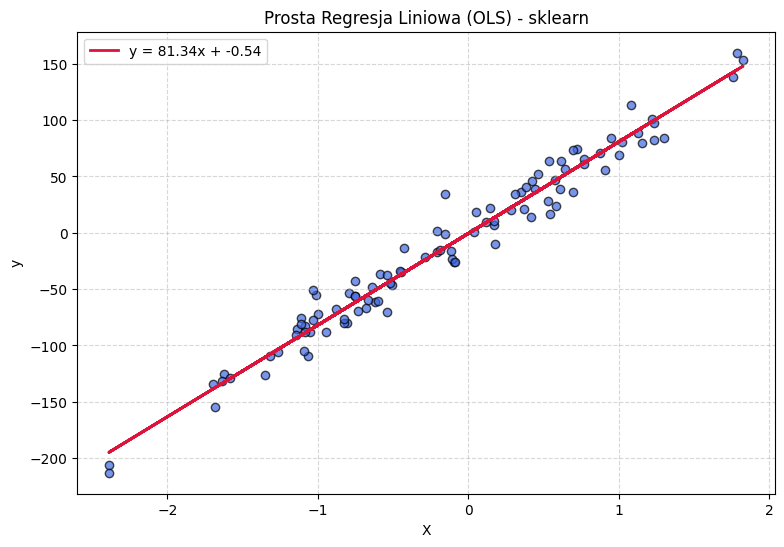

In [7]:
from sklearn.linear_model import LinearRegression

sklearn_model = LinearRegression()
sklearn_model.fit(X1, y1)

plt.figure(figsize=(9, 6))
plt.scatter(X1, y1, color='royalblue', alpha=0.7, edgecolors='k', label='')

y_pred_sk1 = sklearn_model.predict(X1)

plt.plot(X1, y_pred_sk1, color='crimson', linewidth=2, label=f'y = {custom_model.slope_:.2f}x + {custom_model.intercept_:.2f}')

plt.title('Prosta Regresja Liniowa (OLS) - sklearn', fontsize=12)
plt.xlabel('X')
plt.ylabel('y')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

Regresja wielokrotna
$$\hat{y} = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \dots + \beta_n x_n$$

In [8]:
path = kagglehub.dataset_download("altavish/boston-housing-dataset")

csv_files = [f for f in os.listdir(path) if f.endswith('.csv')]
file_path = os.path.join(path, csv_files[0])

df = pd.read_csv(file_path)

df.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,NaN,36.2


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     486 non-null    float64
 1   ZN       486 non-null    float64
 2   INDUS    486 non-null    float64
 3   CHAS     486 non-null    float64
 4   NOX      506 non-null    float64
 5   RM       506 non-null    float64
 6   AGE      486 non-null    float64
 7   DIS      506 non-null    float64
 8   RAD      506 non-null    int64  
 9   TAX      506 non-null    int64  
 10  PTRATIO  506 non-null    float64
 11  B        506 non-null    float64
 12  LSTAT    486 non-null    float64
 13  MEDV     506 non-null    float64
dtypes: float64(12), int64(2)
memory usage: 55.5 KB


beta_0: 32.6801
  Cecha       Beta
     RM   4.283252
   CHAS   2.769378
    RAD   0.285866
     ZN   0.048905
  INDUS   0.030379
      B   0.009656
    AGE  -0.012991
    TAX  -0.013146
   CRIM  -0.097594
  LSTAT  -0.423661
PTRATIO  -0.914582
    DIS  -1.458510
    NOX -17.969028


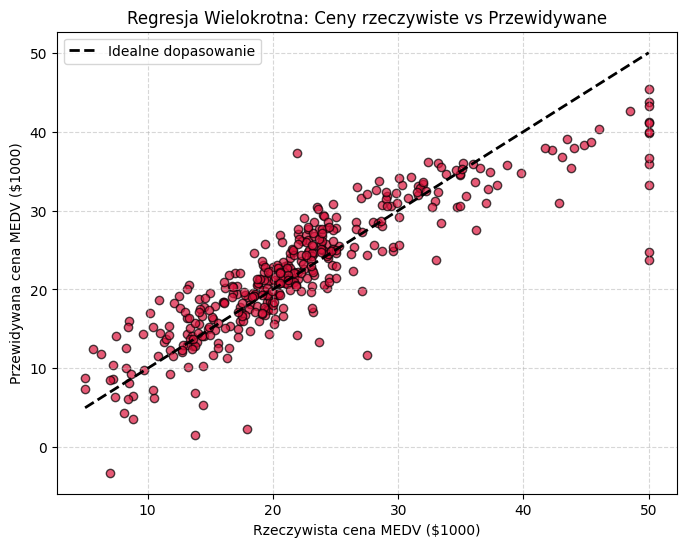

In [10]:
df = df.dropna()

X2 = df.drop(columns=['MEDV'])
y2 = df['MEDV']

model = LinearRegression()
model.fit(X2, y2)

y_pred2 = model.predict(X2)

coef_df = pd.DataFrame({
    'Cecha': X2.columns,
    'Beta': model.coef_
}).sort_values(by='Beta', ascending=False)

print(f"beta_0: {model.intercept_:.4f}")
print(coef_df.to_string(index=False))

plt.figure(figsize=(8, 6))
plt.scatter(y2, y_pred2, alpha=0.7, color='crimson', edgecolors='k')
plt.plot(
    [y2.min(), y2.max()], 
    [y2.min(), y2.max()], 
    'k--', lw=2, label='Idealne dopasowanie'
)

plt.xlabel('Rzeczywista cena MEDV ($1000)')
plt.ylabel('Przewidywana cena MEDV ($1000)')
plt.title('Regresja Wielokrotna: Ceny rzeczywiste vs Przewidywane')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## Zadanie 3

$$\text{MSE} = \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2$$
$$\text{MAE} = \frac{1}{n} \sum_{i=1}^{n} \vert{}y_i - \hat{y}_i\vert{}$$
$$\text{RMSE} = \sqrt{\text{MSE}}$$
$$R^2 = \frac{\text{Cov}(y, \hat{y})^2}{\text{Var}(y) \cdot \text{Var}(\hat{y})}$$

In [11]:
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

mse = mean_squared_error(y1, y_pred1)
mae = mean_absolute_error(y1, y_pred1)
rmse = np.sqrt(mse)
r2 = r2_score(y1, y_pred1)

print('Metryki do zadania 1')
print(f"MSE: {mse:.4f}")
print(f"MAE: {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²: {r2:.4f}")


Metryki do zadania 1
MSE: 186.4549
MAE: 10.7442
RMSE: 13.6548
R²: 0.9676


In [12]:
mse = mean_squared_error(y2, y_pred2)
mae = mean_absolute_error(y2, y_pred2)
rmse = np.sqrt(mse)
r2 = r2_score(y2, y_pred2)

print('Metryki do zadania 2')
print(f"MSE: {mse:.4f}")
print(f"MAE: {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²: {r2:.4f}")

Metryki do zadania 2
MSE: 19.4184
MAE: 3.0644
RMSE: 4.4066
R²: 0.7671


## Zadanie 4

            Cecha  Linear Regression  Ridge (L2)  Lasso (L1)
Cecha_główna (X1)          81.060966   68.681545   78.337836
           Szum_1          -2.561474   -3.014843   -0.000000
           Szum_2          -3.629788   -3.617910   -0.499772
           Szum_3           1.601843    0.472803    0.000000


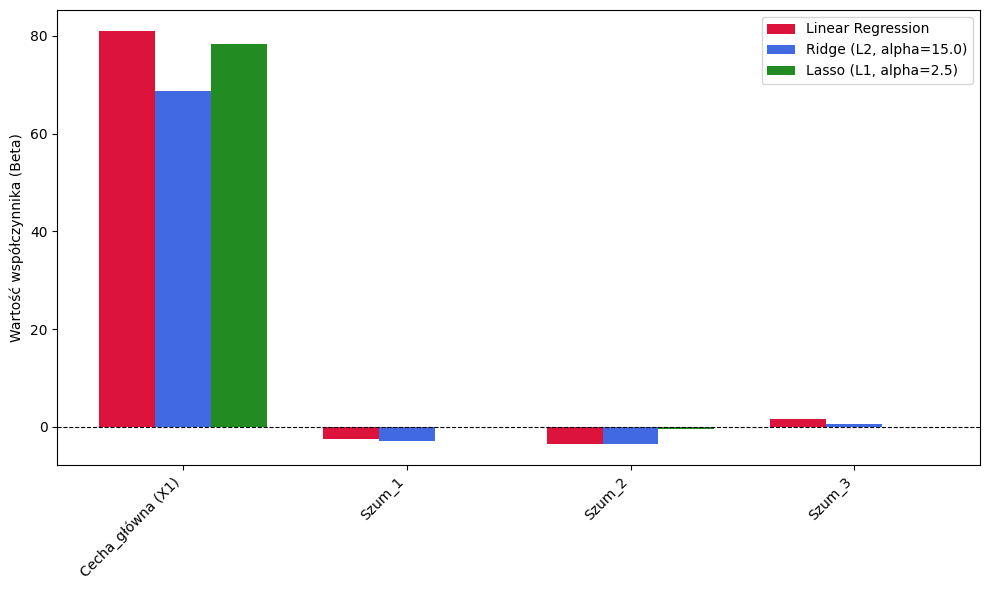

In [13]:
from sklearn.linear_model import Ridge, Lasso

n_noise = 3
alpha_ridge = 15.0
alpha_lasso = 2.5

np.random.seed(67)
n_samples = X1.shape[0]
szum = np.random.normal(loc=0, scale=1, size=(n_samples, n_noise))
X_noisy = np.hstack([X1, szum])

feature_names = ['Cecha_główna (X1)'] + [f'Szum_{i}' for i in range(1, n_noise + 1)]

model_lr = LinearRegression().fit(X_noisy, y1)
model_ridge = Ridge(alpha=alpha_ridge).fit(X_noisy, y1)
model_lasso = Lasso(alpha=alpha_lasso).fit(X_noisy, y1)

df_coefs = pd.DataFrame({
    'Cecha': feature_names,
    'Linear Regression': model_lr.coef_,
    'Ridge (L2)': model_ridge.coef_,
    'Lasso (L1)': model_lasso.coef_
})

print(df_coefs.to_string(index=False))

plt.figure(figsize=(max(10, n_noise * 0.7), 6))
x_indices = np.arange(len(feature_names))
bar_width = 0.25

plt.bar(x_indices - bar_width, model_lr.coef_, width=bar_width, label='Linear Regression', color='crimson')
plt.bar(x_indices, model_ridge.coef_, width=bar_width, label=f'Ridge (L2, alpha={alpha_ridge})', color='royalblue')
plt.bar(x_indices + bar_width, model_lasso.coef_, width=bar_width, label=f'Lasso (L1, alpha={alpha_lasso})', color='forestgreen')

plt.xticks(x_indices, feature_names, rotation=45, ha='right')
plt.axhline(0, color='black', linewidth=0.8, linestyle='--')
plt.ylabel('Wartość współczynnika (Beta)')
plt.legend()
plt.tight_layout()
plt.show()

=== Porównanie współczynników w obecności multikolinearności ===
             Cecha  Linear Regression  Ridge (L2)  Lasso (L1)
 Cecha_główna (X1)          95.952819   27.962274   78.369113
Szum_Skorelowany_1         -12.432712   24.730354    0.000000
Szum_Skorelowany_2          -2.277192   25.475780    0.000000
       Szum_Losowy          -0.869070   -1.320752   -0.000000


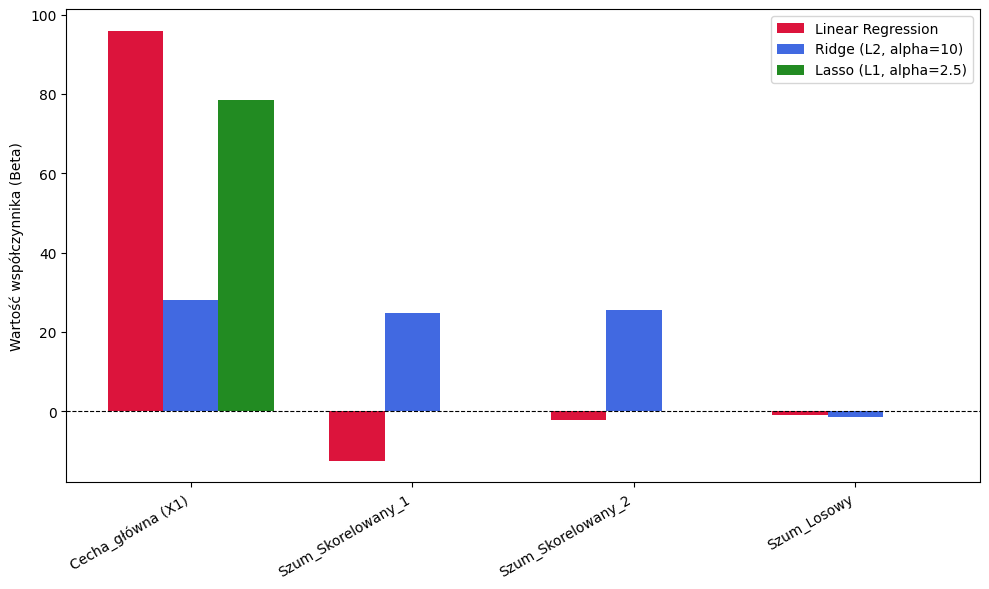

In [14]:
np.random.seed(67)
szum_skorelowany_1 = X1 + np.random.normal(loc=0, scale=0.1, size=X1.shape)
szum_skorelowany_2 = X1 + np.random.normal(loc=0, scale=0.1, size=X1.shape)
szum_czysty_losowy = np.random.normal(loc=0, scale=1.0, size=X1.shape)

X_noisy = np.hstack([X1, szum_skorelowany_1, szum_skorelowany_2, szum_czysty_losowy])
feature_names = ['Cecha_główna (X1)', 'Szum_Skorelowany_1', 'Szum_Skorelowany_2', 'Szum_Losowy']

model_lr = LinearRegression().fit(X_noisy, y1)
model_ridge = Ridge(alpha=10.0).fit(X_noisy, y1)
model_lasso = Lasso(alpha=2.5).fit(X_noisy, y1)

df_coefs = pd.DataFrame({
    'Cecha': feature_names,
    'Linear Regression': model_lr.coef_,
    'Ridge (L2)': model_ridge.coef_,
    'Lasso (L1)': model_lasso.coef_
})

print("=== Porównanie współczynników w obecności multikolinearności ===")
print(df_coefs.to_string(index=False))

plt.figure(figsize=(10, 6))
x_indices = np.arange(len(feature_names))
bar_width = 0.25

plt.bar(x_indices - bar_width, model_lr.coef_, width=bar_width, label='Linear Regression', color='crimson')
plt.bar(x_indices, model_ridge.coef_, width=bar_width, label='Ridge (L2, alpha=10)', color='royalblue')
plt.bar(x_indices + bar_width, model_lasso.coef_, width=bar_width, label='Lasso (L1, alpha=2.5)', color='forestgreen')

plt.xticks(x_indices, feature_names, rotation=30, ha='right')
plt.axhline(0, color='black', linewidth=0.8, linestyle='--')
plt.ylabel('Wartość współczynnika (Beta)')
plt.legend()
plt.tight_layout()
plt.show()

## Zadanie 5

Funkcja sigmoidalna
$$\sigma(x) = \frac{1}{1 + e^{-x}}$$

In [15]:
def sigmoid(x):
    return 1/(1 + np.exp(-x))

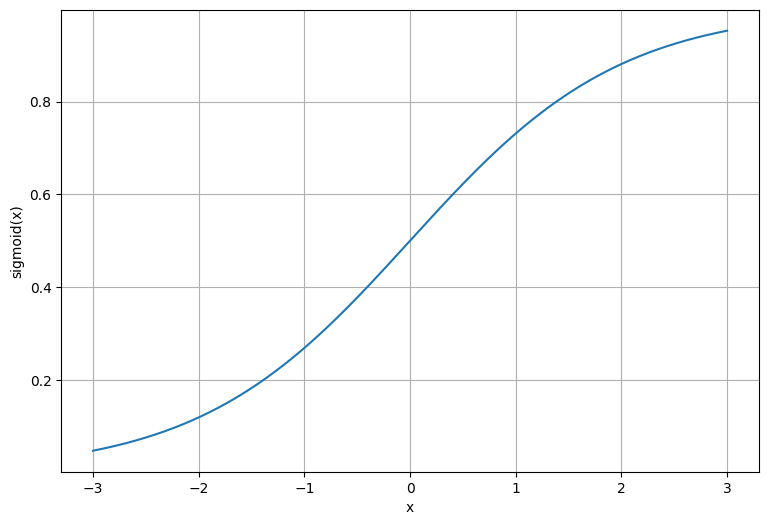

In [16]:
xd = np.linspace(-3, 3, 1000)

plt.figure(figsize=(9, 6))
plt.plot(xd, sigmoid(xd))
plt.xlabel('x')
plt.ylabel('sigmoid(x)')
plt.grid()

## Zadanie 6

In [17]:
path = kagglehub.dataset_download("yasserh/titanic-dataset")

file_path = os.path.join(path, "Titanic-Dataset.csv")

titanic_df = pd.read_csv(file_path)

titanic_df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [33]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

df = titanic_df.drop(columns=['PassengerId', 'Name', 'Ticket', 'Cabin'])

df['Age'] = df['Age'].fillna(df['Age'].median())
df = df.dropna(subset=['Embarked'])

df['Sex'] = df['Sex'].map({'female': 0, 'male': 1})
df = pd.get_dummies(df, columns=['Embarked'], drop_first=True, dtype=int)

X = df.drop(columns=['Survived'])
y = df['Survived']
print(y.value_counts())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=67, stratify=y
)
print(y_test.value_counts())
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = LogisticRegression(random_state=67)
model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]


Survived
0    549
1    340
Name: count, dtype: int64
Survived
0    110
1     68
Name: count, dtype: int64


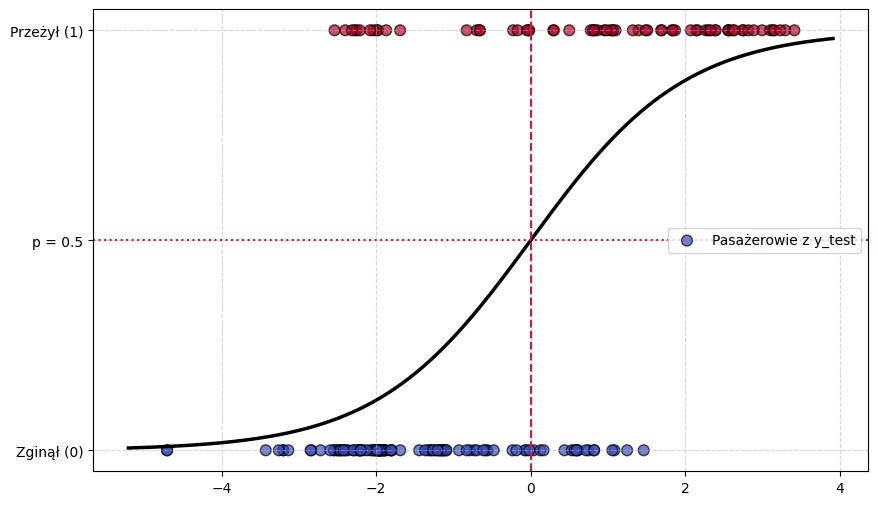

In [31]:
z_test = model.decision_function(X_test_scaled)

z_range = np.linspace(z_test.min() - 0.5, z_test.max() + 0.5, 300)
sigmoid_curve = 1 / (1 + np.exp(-z_range))

plt.figure(figsize=(10, 6))

plt.scatter(
    z_test, y_test, 
    c=y_test, cmap='coolwarm', alpha=0.7, edgecolors='k', s=60, 
    label='Pasażerowie z y_test'
)

plt.plot(
    z_range, sigmoid_curve, 
    color='black', linewidth=2.5, 
)

plt.axvline(0, color='crimson', linestyle='--', linewidth=1.5)
plt.axhline(0.5, color='crimson', linestyle=':', linewidth=1.5)

plt.yticks([0, 0.5, 1.0], ['Zginął (0)', 'p = 0.5', 'Przeżył (1)'])
plt.legend(loc='center right', frameon=True)
plt.grid(True, linestyle='--', alpha=0.5)

plt.show()

## Zadanie 7

- $TN$ - true negative (Rzeczywistość: pasażer zginął, Model: pasażer zginął)
- $FN$ - false positive (Rzeczywistość: pasażer przeżył, Model: pasażer zginął)
- $FP$ - false negative (Rzeczywistość: pasażer zginął, Model: pasażer przeżył)
- $TP$ - true positive (Rzeczywistość: pasażer przeżył, Model: pasażer przeżył)


$$\mathbf{CM} = \begin{bmatrix} \text{TN} & \text{FP} \\ \text{FN} & \text{TP} \end{bmatrix}$$
$$\text{Accuracy} = \frac{\text{TP} + \text{TN}}{\text{TP} + \text{TN} + \text{FP} + \text{FN}}$$
$$\text{Precision} = \frac{\text{TP}}{\text{TP} + \text{FP}}$$
$$\text{Recall} = \frac{\text{TP}}{\text{TP} + \text{FN}}$$

In [26]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix

cm = confusion_matrix(y_test, y_pred)
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)

print("Macierz pomyłek")
print("TN", "FP")
print(cm)
print("FN", "TP")

print(f"Dokładność (Accuracy): {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"Precyzja (Precision):  {precision:.4f} ({precision*100:.2f}%)")
print(f"Czułość (Recall):       {recall:.4f} ({recall*100:.2f}%)")

Macierz pomyłek
TN FP
[[93 17]
 [21 47]]
FN TP
Dokładność (Accuracy): 0.7865 (78.65%)
Precyzja (Precision):  0.7344 (73.44%)
Czułość (Recall):       0.6912 (69.12%)
